# Extension Notebook 
Nora Lif Masi & Anton Wallin\
Machine Learning & Language Models 

As our extension, we wanted to dive deeper into the brain predictibility of BERT embeddings on ROI's. To acheive an innovative research design, we decided to expand the predictibility investigation to three ROI's. Our motivation in selecting the ROI's was based on their respective responsibility for diverse levels of language processing. The three ROI's that we have chosen are: Fusiform Face Area, Language Left Hemisphere, and Semantic AAL. These correspond to responsibilities across low-level, mid/general-level, and high-level linguistic processing. In addition to uncovering the brain predictibility of embeddings on these ROI's, we decided to incorporate the linguistic feature predictibility measures from the original notebook. These are sentence length and sentence topic. We would like to explore the layer-wise distributions of predictibility on ROI's and linguistic features. Are layers representative of low-level features also predictive of low-level ROI's and vice versa?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from transformers import AutoModel, AutoTokenizer
from scipy.stats import false_discovery_control
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

/gpfs/home1/scur0583/MLLM_Project/project2/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Define participants and load the dataset of the experiment. 

In [2]:
participants = ['P01', 'M02', 'M04', 'M07', 'M08', 'M09', 'M14', 'M15']

data = {participant: loadmat(f'pereira_dataset/{participant}/data_384sentences.mat', simplify_cells=True) for participant in participants}

# 0. Defining the class and loading BERT embeddings

In [3]:
class Experiment2Data:
    """
    Provides structured access to fMRI experiment data containing brain
    responses (betas) to sentence and passage stimuli, along with metadata
    about brain networks, topics, and stimulus labels.

    Attributes
    ----------
    betas : dict
        Beta (activation) arrays keyed by stimulus type:
        - 'sentence': betas for individual sentences
        - 'passage' : betas for full passages
    networks : np.ndarray
        Array of atlas/network names from the experiment metadata.
    experiment_data : dict
        The full raw experiment data dictionary.
    sentences : np.ndarray
        Array of all individual sentences used as stimuli.
    topics : list
        Ordered list of passage topic/category labels.
    """

    def __init__(self, experiment_data):
        """
        Parameters
        ----------
        experiment_data : dict
            Raw data dictionary expected to contain:
            - 'examples_passagesentences' : betas for sentence-level stimuli
            - 'examples_passages'         : betas for passage-level stimuli
            - 'meta'                      : dict with 'atlases' and 'roiColumns'
            - 'keySentences'              : array of sentence strings
            - 'keyPassageCategory'        : array of topic/category labels
        """
        self.betas = {
            'sentence': experiment_data['examples_passagesentences'],
            'passage':  experiment_data['examples_passages'],
        }
        # networks like languageRH
        self.networks = experiment_data['meta']['atlases']
        # ROIs like L_AFF
        self.rois = experiment_data['meta']['rois'][0]
        # data
        self.experiment_data = experiment_data
        # sentences
        self.sentences = experiment_data['keySentences']
        # passages with category mask
        self.topics = experiment_data['keyPassageCategory'].tolist()

    def get_roi_mask(self, network, stimulus_type):
        # Check whether the input is an atlas/network
        if network in self.networks:
            target_index = np.where(self.networks == network)[0].item()

            column_indexes = np.concat(
                [ind - 1 for ind in self.experiment_data['meta']['roiColumns'][target_index]],
                axis=0,
            )
            return column_indexes

        # Otherwise, search for the ROI within each atlas
        for target_index, rois in enumerate(self.experiment_data['meta']['rois']):
            if network in rois:
                roi_index = np.where(rois == network)[0].item()

                column_indexes = (
                    self.experiment_data['meta']['roiColumns'][target_index][roi_index] - 1
                )
                return column_indexes

        raise ValueError(f"{network} is neither a network nor an ROI.")


    def get_passage(self, passage_id):
        """
        Reconstruct the full text of a passage by joining its sentences.

        Parameters
        ----------
        passage_id : int
            The numeric ID of the passage to retrieve.

        Returns
        -------
        str
            The passage text as a single space-joined string.
        """
        # Select all sentences that belong to the given passage
        sentences = self.sentences[
            self.experiment_data['labelsPassageForEachSentence'] == passage_id
        ]
        return ' '.join(sentences)

    def get_topic_list(self, stimulus_type):
        """
        Return a topic/category label for every stimulus of the given type.

        For passages, returns the category label array directly.
        For sentences, maps each sentence to the category of its parent passage.

        Parameters
        ----------
        stimulus_type : str
            Either 'passage' (one label per passage) or 'sentence'
            (one label per sentence).

        Returns
        -------
        np.ndarray of int
            Integer category labels aligned with the stimuli of the given type.
        """
        if stimulus_type == 'passage':
            return self.experiment_data['labelsPassageCategory']

        elif stimulus_type == 'sentence':
            categories = np.unique(
                self.experiment_data['labelsPassageCategory'].astype(int)
            )
            topic_vec = np.empty(len(self.sentences))

            for category in categories:
                # Find all passage IDs that belong to this category (1-based)
                relevant_passages = (
                    np.where(self.experiment_data['labelsPassageCategory'] == category)[0] + 1
                )
                # Assign the category label to every sentence from those passages
                for passage_id in relevant_passages:
                    topic_vec[
                        self.experiment_data['labelsPassageForEachSentence'] == passage_id
                    ] = category

            return topic_vec.astype(int)


    def get_topic_mask(self, topic, stimulus_type):
        """
        Return the indices of all stimuli belonging to a given topic.

        Parameters
        ----------
        topic : str
            Topic name as it appears in self.topics (e.g. 'science').
        stimulus_type : str
            Either 'passage' (returns passage indices) or 'sentence'
            (returns sentence indices).

        Returns
        -------
        np.ndarray or list of int
        
            - 'passage' : 1-based array of passage IDs for the topic.
            - 'sentence': list of 0-based sentence indices whose parent
              passage belongs to the topic.
        """
        # Convert topic name to its 1-based category ID
        target_topic_id = self.topics.index(topic) + 1

        # Find all passages assigned to this category (1-based IDs)
        relevant_passages = (
            np.where(self.experiment_data['labelsPassageCategory'] == target_topic_id)[0] + 1
        )

        if stimulus_type == 'passage':
            return relevant_passages
        elif stimulus_type == 'sentence':
            # Return 0-based sentence indices whose passage ID is in the relevant set
            return [
                i for i, ind in enumerate(self.experiment_data['labelsPassageForEachSentence'])
                if ind in relevant_passages
            ]


We first store the right indices for the three brain regions we want to look at, different indices for each participant as the number of voxel varies per participant.

In [4]:
target_indices = {}
# notice that L_FFA is a roi, not a network, 
# which is why we had to adapt the function of the class to cover all usecases
regions = ['languageLH', 'L_FFA', 'semantic_aal']

for participant in participants:
    target_indices[participant] = {}
    participant_data = data[participant]
    exp = Experiment2Data(data[participant])

    for region in regions:
        column_indexes = exp.get_roi_mask(region, 'sentence')
        target_indices[participant][region] = column_indexes

Now we store the betas of the different participants in a dictionary to make them easily accessible later.

In [5]:
betas = {}

for participant in participants:
    betas[participant] = {}

    exp = Experiment2Data(data[participant])

    for region in regions:
        region_indices = target_indices[participant][region]

        betas[participant][region] = (
            exp.betas['sentence'][:, region_indices]
        )

Store some information that doesn't vary across participants and will be needed later.

In [6]:
exp = Experiment2Data(data['M02'])
sentences = exp.sentences
topic_list = exp.get_topic_list('sentence')

Here, we want to get the BERT embeddings of all of the 180 sentences that were present in Experiment 2. The pooling method used to obtain these embeddings was the CLS token selection. We use the embeddings from the notebook

In [7]:
embeddings = np.load('pooled_embbeding_array.npy')

# 1. Embedding predictibility on sentences

# 1.1. The LanguageLH Network ROI

First, we observe the mean brain predictivity of all BERT layers across the participants in the LH language network. To properly manage the data for all participants we decided to create numpy arrays of which the size is determined by the maximal amount of voxels we will need to store. 

In [8]:
# Assess how many voxels we will have at most in this brain region
indices_languageLH = np.empty(len(participants))
# loop over participants
for i, participant in enumerate(participants):
    part_languageLH_indices = target_indices[participant]['languageLH']
    # store the number of voxels of the languageLH network of participant i
    indices_languageLH[i] = part_languageLH_indices.shape[0]

# find the participant with the most voxels
max_voxel_participant = np.argmax(indices_languageLH)
# find the number of voxels of said participant
max_voxels = len(target_indices[participants[max_voxel_participant]]['languageLH'])
print(f"Maximal numbers of voxels in the languageLH network: {max_voxels}")

Maximal numbers of voxels in the languageLH network: 5906


Now we predict the betas of each voxel of each participant using ridge regression.

In [9]:
# create an empty array to store the betas 
# the first three dimension correspond to 8 participants, 13 layers and 384 stimuli
all_participants_predictions_per_layer_language = np.full((8,13,384,max_voxels), np.nan)
# Instantiate kfold with 5 splits
kf = KFold(n_splits=5, shuffle=True, random_state=42)
kf.get_n_splits()

# loop over participants
for i, participant in enumerate(participants):
  languageLH_betas = betas[participant]['languageLH']
  participant_n_voxels = languageLH_betas.shape[1]

  # create an empty array to store predictions for all layers
  all_layer_predictions_array = all_participants_predictions_per_layer_language[i]

  # loop over embeddings layer-wise
  for j in range(13):
    # get the embeddings of the current layer
    this_layer_embeddings = embeddings[j]

    # loop over folds
    for k, (train_index, test_index) in enumerate(kf.split(this_layer_embeddings)):
      # obtain train and test partitions
      x_train, x_test = this_layer_embeddings[train_index], this_layer_embeddings[test_index]
      y_train, y_test = languageLH_betas[train_index], languageLH_betas[test_index]
      # fit Ridge regression
      language_ridge = RidgeCV(alphas=np.logspace(1, 20, 40), alpha_per_target=True)
      language_ridge.fit(x_train, y_train)
      # Compute predictions
      language_preds = language_ridge.predict(x_test)
      # store predictions 
      all_layer_predictions_array[j, test_index, :participant_n_voxels] = language_preds

To assess performance of the model we compute the $R^2$ values on the predictions. 
To make sure that we are only considering significant voxels, we instantiate a permutation test and leave out voxels with p-values surpassing the Benjamini-Hochberg threshold.

In [10]:
# create empty arrays to store R^2s and R^2s on significant voxels
r2s_languageLH = np.full((len(participants), 13, max_voxels), np.nan)
r2_signif_per_layer_and_participant = np.full((len(participants), 13), np.nan)

num_permutations = 1000
np.random.seed(10)

# loop over participants
for j, participant in enumerate(participants):
    # get participant specific information
    participant_betas = betas[participant]['languageLH']
    n_voxels = participant_betas.shape[1]
    n_stimuli = participant_betas.shape[0]

    # loop over predictions layer-wise
    for i in range(13):
        preds = all_participants_predictions_per_layer_language[j, i, :, :n_voxels]

        # calculate the actual R² for each voxel
        r2 = r2_score(participant_betas, preds, multioutput='raw_values')
        r2s_languageLH[j, i, :n_voxels] = r2

        # permutation test
        permuted_r2s = np.empty((num_permutations, n_voxels))

        for k in range(num_permutations):
            # shuffle the predictions across stimuli
            inds = np.random.choice(n_stimuli, size=n_stimuli, replace=False)

            perm_r2 = r2_score(participant_betas, preds[inds], multioutput='raw_values')
            permuted_r2s[k] = perm_r2

        # calculate p-values for each voxel
        p_vals = ((permuted_r2s >= r2).sum(axis=0) + 1) / (num_permutations + 1)

        # correct for multiple comparisons across voxels
        corrected_pvals = false_discovery_control(p_vals)

        # store significant voxel results
        significant_pvals = corrected_pvals < 0.05

        if significant_pvals.any():
            r2_signif_per_layer_and_participant[j, i] = r2[significant_pvals].mean()
        else:
            print(f"No significant voxels found at layer {i} for participant {participant}")

        print(
            f"{participant}, layer {i}: "
            f"significant voxels before correction = {(p_vals < 0.05).sum()}, "
            f"after correction = {significant_pvals.sum()}"
        )

No significant voxels found at layer 0 for participant P01
P01, layer 0: significant voxels before correction = 0, after correction = 0
P01, layer 1: significant voxels before correction = 3607, after correction = 3504
P01, layer 2: significant voxels before correction = 3891, after correction = 3780
P01, layer 3: significant voxels before correction = 3835, after correction = 3741
P01, layer 4: significant voxels before correction = 4076, after correction = 4006
P01, layer 5: significant voxels before correction = 4275, after correction = 4222
P01, layer 6: significant voxels before correction = 4371, after correction = 4293
P01, layer 7: significant voxels before correction = 4267, after correction = 4220
P01, layer 8: significant voxels before correction = 4303, after correction = 4223
P01, layer 9: significant voxels before correction = 4300, after correction = 4240
P01, layer 10: significant voxels before correction = 3969, after correction = 3855
P01, layer 11: significant voxels

We now calculate mean values of the $R^2$ metric, computing this for each layer across all voxels and participants.

In [11]:
# Mean R2 across voxels, for each participant and layer
mean_r2_per_participant_languageLH = np.nanmean(r2s_languageLH, axis=2)
# Mean R2 across participants, for each layer
mean_r2_languageLH = np.nanmean(mean_r2_per_participant_languageLH, axis=0)

# Mean R2 of significant voxels, across participants
mean_significant_r2_languageLH = np.nanmean(r2_signif_per_layer_and_participant, axis=0)
# Delete the first layer from the significant r2s
mean_significant_r2_no_first_languageLH = np.delete(mean_significant_r2_languageLH, 0)

# save data that will be needed for plotting and statistical tests 
# (in case we need to rerun them without wanting to rerun the complete notebook)
np.save('mean_r2_languageLH.npy', mean_r2_languageLH)
np.save('mean_significant_r2_no_first_languageLH.npy', mean_significant_r2_no_first_languageLH)

/scratch-local/scur0583.28277218/ipykernel_380438/2216039722.py:7: RuntimeWarning: Mean of empty slice
  mean_significant_r2_languageLH = np.nanmean(r2_signif_per_layer_and_participant, axis=0)


To plot the results, we leave out the first layer (layer 0), as it is just an embedding layer and is therefore not relevant to the task. Additionally, as you can see above, no significant voxels were found in any of the participants at layer 0, so plotting it would only add unnecessary data to the graph. 

Best layer for the languageLH network: 5
R^2 value on the best layer: 0.053
Mean R^2 value on significant voxels: 0.047


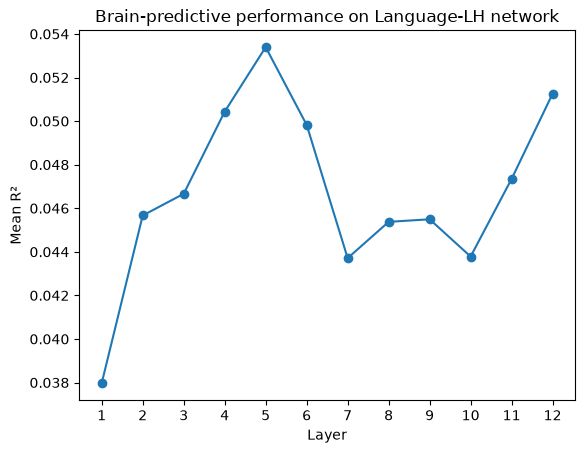

In [12]:
best_layer_language = np.argmax(mean_significant_r2_no_first_languageLH) +1
print(f"Best layer for the languageLH network: {best_layer_language}")
print(f"R^2 value on the best layer: {mean_significant_r2_no_first_languageLH[best_layer_language-1]:.3f}")
print(f"Mean R^2 value on significant voxels: {np.mean(mean_significant_r2_no_first_languageLH):.3f}")

# Plot layer-wise R2s
plt.plot(range(1, 13), mean_significant_r2_no_first_languageLH, marker='o')
plt.xlabel('Layer')
plt.ylabel('Mean R²')
plt.title('Brain-predictive performance on Language-LH network')
plt.xticks(range(1,13))
plt.show()

# 1.2. The L FFA ROI

In [20]:
# Assess how many voxels we will have at most in this brain region
indices_LFFA = np.empty(len(participants))
# loop over participants
for i, participant in enumerate(participants):
    part_indices_LFFA = target_indices[participant]['L_FFA']
    # store the number of voxels of the L FFA ROI of participant i
    indices_LFFA[i] = part_indices_LFFA.shape[0]

# find the participant with the most voxels
visual_max_voxel_participant = np.argmax(indices_LFFA)
# find the number of voxels of said participant
visual_max_voxels = len(target_indices[participants[visual_max_voxel_participant]]['L_FFA'])
print(f"Maximal numbers of voxels in the L_FFA ROI: {visual_max_voxels}")

Maximal numbers of voxels in the L_FFA ROI: 639


In [21]:
# create an empty array to store the betas 
# the first three dimension correspond to 8 participants, 13 layers and 384 stimuli
all_participants_predictions_per_layer_LFFA = np.full((8,13,384,visual_max_voxels), np.nan)
# Instantiate kfold with 5 splits
kf = KFold(n_splits=5, shuffle=True, random_state=42)
kf.get_n_splits()

# loop over participants
for i, participant in enumerate(participants):
  visual_betas = betas[participant]['L_FFA']
  participant_n_voxels = visual_betas.shape[1]

  # create an empty array to store predictions for all layers
  all_layer_predictions_array = all_participants_predictions_per_layer_LFFA[i]

  # loop over embeddings layer-wise
  for j in range(13):
    # get the embeddings of the current layer
    this_layer_embeddings = embeddings[j]
    
    # Loop over folds
    for k, (train_index, test_index) in enumerate(kf.split(this_layer_embeddings)):
        # Obtain train and test partitions
      x_train, x_test = this_layer_embeddings[train_index], this_layer_embeddings[test_index]
      y_train, y_test = visual_betas[train_index], visual_betas[test_index]
      # Fit Ridge regression
      visual_ridge = RidgeCV(alphas=np.logspace(1, 20, 40), alpha_per_target=True)
      visual_ridge.fit(x_train, y_train)
      # Compute predictions
      visual_preds = visual_ridge.predict(x_test)
      # Store predictions
      all_layer_predictions_array[j, test_index, :participant_n_voxels] = visual_preds

In [22]:
# Create empty arrays to store R^2s and R^2s on significant voxels
r2s_LFFA = np.full((len(participants), 13, visual_max_voxels), np.nan)
r2_signif_per_layer_and_participant = np.full((len(participants), 13), np.nan)

num_permutations = 1000
np.random.seed(10)

# loop over participants
for j, participant in enumerate(participants):
    # get participant specific information
    participant_betas = betas[participant]['L_FFA']
    n_voxels = participant_betas.shape[1]
    n_stimuli = participant_betas.shape[0]

    # Loop over predictions layer-wise
    for i in range(13):
        preds = all_participants_predictions_per_layer_LFFA[j, i, :, :n_voxels]

        # Calculate the actual R² for each voxel
        r2 = r2_score(participant_betas, preds, multioutput='raw_values')
        r2s_LFFA[j, i, :n_voxels] = r2

        # Permutation test
        permuted_r2s = np.empty((num_permutations, n_voxels))

        for k in range(num_permutations):
            # Shuffle predictions across stimuli
            inds = np.random.choice(n_stimuli, size=n_stimuli, replace=False)

            perm_r2 = r2_score(participant_betas, preds[inds], multioutput='raw_values')
            permuted_r2s[k] = perm_r2

        # Calculate p-values for each voxel
        p_vals = ((permuted_r2s >= r2).sum(axis=0) + 1) / (num_permutations + 1)

        # Correct for multiple comparisons across voxels
        corrected_pvals = false_discovery_control(p_vals)

        # Store significant voxel results
        significant_pvals = corrected_pvals < 0.05

        if significant_pvals.any():
            r2_signif_per_layer_and_participant[j, i] = r2[significant_pvals].mean()
        else:
            print(f"No significant voxels found at layer {i} for participant {participant}")

        print(
            f"{participant}, layer {i}: "
            f"significant voxels before correction = {(p_vals < 0.05).sum()}, "
            f"after correction = {significant_pvals.sum()}"
        )

No significant voxels found at layer 0 for participant P01
P01, layer 0: significant voxels before correction = 0, after correction = 0
P01, layer 1: significant voxels before correction = 499, after correction = 481
P01, layer 2: significant voxels before correction = 551, after correction = 542
P01, layer 3: significant voxels before correction = 534, after correction = 514
P01, layer 4: significant voxels before correction = 454, after correction = 432
P01, layer 5: significant voxels before correction = 562, after correction = 553
P01, layer 6: significant voxels before correction = 634, after correction = 634
P01, layer 7: significant voxels before correction = 638, after correction = 638
P01, layer 8: significant voxels before correction = 638, after correction = 638
P01, layer 9: significant voxels before correction = 636, after correction = 636
P01, layer 10: significant voxels before correction = 631, after correction = 631
P01, layer 11: significant voxels before correction =

In [23]:
# Mean R² across voxels, for each participant and layer
mean_r2_per_participant_LFFA = np.nanmean(r2s_LFFA, axis=2)
# Mean R² across participants, for each layer
mean_r2_LFFA = np.nanmean(mean_r2_per_participant_LFFA, axis=0)

# Mean R² of significant voxels, across participants
mean_significant_r2 = np.nanmean(r2_signif_per_layer_and_participant, axis=0)
# Delete the first layer from the significant r2s
mean_significant_r2_no_first_LFFA = np.delete(mean_significant_r2, 0)

# save data that will be needed for plotting and statistical tests 
# (in case we need to rerun them without wanting to rerun the complete notebook)
np.save('mean_r2_LFFA.npy', mean_r2_LFFA)
np.save('mean_significant_r2_no_first_LFFA.npy', mean_significant_r2_no_first_LFFA)

/scratch-local/scur0583.28277218/ipykernel_380438/445841357.py:7: RuntimeWarning: Mean of empty slice
  mean_significant_r2 = np.nanmean(r2_signif_per_layer_and_participant, axis=0)


Best layer for the L FFA ROI: 8
R^2 value on the best layer: 0.045
Mean R^2 value on significant voxels: 0.043


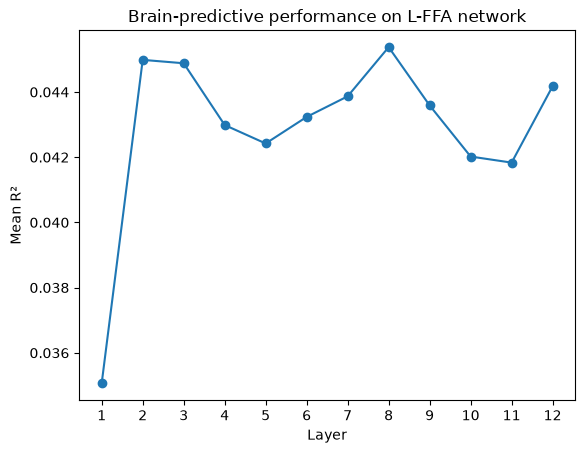

In [24]:
best_layer_visual = np.argmax(mean_significant_r2_no_first_LFFA) + 1
print(f"Best layer for the L FFA ROI: {best_layer_visual}")
print(f"R^2 value on the best layer: {mean_significant_r2_no_first_LFFA[best_layer_visual-1]:.3f}")
print(f"Mean R^2 value on significant voxels: {np.mean(mean_significant_r2_no_first_LFFA):.3f}")

# Plot layer-wise R2s
plt.plot(range(1, 13), mean_significant_r2_no_first_LFFA, marker='o')
plt.xlabel('Layer')
plt.ylabel('Mean R²')
plt.title('Brain-predictive performance on L-FFA network')
plt.xticks(range(1,13))
plt.show()

# 1.3. The AAL Semantic Network ROI

In [10]:
# Assess how many voxels we will have at most in this brain region
semantic_aal_indices = np.empty(len(participants))
# loop over participants
for i, participant in enumerate(participants):
    part_semantic_aal_indices = target_indices[participant]['semantic_aal']
    # store the number of voxels of the semantic AAL network of participant i    
    semantic_aal_indices[i] = part_semantic_aal_indices.shape[0]

# find the participant with the most voxels
semantic_aal_max_voxel_participant = np.argmax(semantic_aal_indices)
# find the number of voxels of said participant
semantic_aal_max_voxels = len(target_indices[participants[semantic_aal_max_voxel_participant]]['semantic_aal'])
print(f"Maximal numbers of voxels in the semantic AAL network: {semantic_aal_max_voxels}")

Maximal numbers of voxels in the semantic AAL network: 11480


In [9]:
# create an empty array to store the betas 
# the first three dimension correspond to 8 participants, 13 layers and 384 stimuli
all_participants_predictions_per_layer_semanticAAL = np.full((8,13,384,semantic_aal_max_voxels), np.nan)
# Instantiate kfold with 5 splits
kf = KFold(n_splits=5, shuffle=True, random_state=42)
kf.get_n_splits()

# loop over participants
for i, participant in enumerate(participants):
  semantic_aal_betas = betas[participant]['semantic_aal']
  participant_n_voxels = semantic_aal_betas.shape[1]

  # Create an empty array to store predictions for all layers
  all_layer_predictions_array = all_participants_predictions_per_layer_semanticAAL[i]

  # Loop over embeddings layer-wise
  for j in range(13):
    # get the embeddings of the current layer
    this_layer_embeddings = embeddings[j]

    # Loop over folds
    for k, (train_index, test_index) in enumerate(kf.split(this_layer_embeddings)):
        # Obtain train and test partitions
      x_train, x_test = this_layer_embeddings[train_index], this_layer_embeddings[test_index]
      y_train, y_test = semantic_aal_betas[train_index], semantic_aal_betas[test_index]
      # Fit Ridge regression
      semantic_ridge = RidgeCV(alphas=np.logspace(1, 20, 40), alpha_per_target=True)
      semantic_ridge.fit(x_train, y_train)
      # Compute predictions 
      semantic_preds = semantic_ridge.predict(x_test)
      # Store predictions
      # Add layer-wise predictions to prediction vector
    
      all_layer_predictions_array[j, test_index, :participant_n_voxels] = semantic_preds

In [11]:
# Create empty arrays to store R^2 and R^2s on significant voxels
r2s_semanticAAL = np.full((len(participants), 13, semantic_aal_max_voxels), np.nan)
r2_signif_per_layer_and_participant = np.full((len(participants), 13), np.nan)

num_permutations = 1000
np.random.seed(10)

# loop over participants
for j, participant in enumerate(participants):
    # get participant specific information
    participant_betas = betas[participant]['semantic_aal']
    n_voxels = participant_betas.shape[1]
    n_stimuli = participant_betas.shape[0]

    # Loop over predictions layer-wise
    for i in range(13):
        preds = all_participants_predictions_per_layer_semanticAAL[j, i, :, :n_voxels]

        # Calculate the actual R² for each voxel
        r2 = r2_score(participant_betas, preds, multioutput='raw_values')
        r2s_semanticAAL[j, i, :n_voxels] = r2

        # Permutation test
        permuted_r2s = np.empty((num_permutations, n_voxels))

        for k in range(num_permutations):
            # Shuffle predictions across stimuli
            inds = np.random.choice(n_stimuli, size=n_stimuli, replace=False)

            perm_r2 = r2_score(participant_betas, preds[inds], multioutput='raw_values')
            permuted_r2s[k] = perm_r2

        # Calculate p-values for each voxel
        p_vals = ((permuted_r2s >= r2).sum(axis=0) + 1) / (num_permutations + 1)

        # Correct for multiple comparisons across voxels
        corrected_pvals = false_discovery_control(p_vals)

        # Store significant voxel results
        significant_pvals = corrected_pvals < 0.05

        if significant_pvals.any():
            r2_signif_per_layer_and_participant[j, i] = r2[significant_pvals].mean()
        else:
            print(f"No significant voxels found at layer {i} for participant {participant}")

        print(
            f"{participant}, layer {i}: "
            f"significant voxels before correction = {(p_vals < 0.05).sum()}, "
            f"after correction = {significant_pvals.sum()}"
        )

No significant voxels found at layer 0 for participant P01
P01, layer 0: significant voxels before correction = 0, after correction = 0
P01, layer 1: significant voxels before correction = 7608, after correction = 7356
P01, layer 2: significant voxels before correction = 8234, after correction = 8028
P01, layer 3: significant voxels before correction = 8115, after correction = 7898
P01, layer 4: significant voxels before correction = 8832, after correction = 8688
P01, layer 5: significant voxels before correction = 9257, after correction = 9132
P01, layer 6: significant voxels before correction = 9443, after correction = 9318
P01, layer 7: significant voxels before correction = 9284, after correction = 9164
P01, layer 8: significant voxels before correction = 9319, after correction = 9187
P01, layer 9: significant voxels before correction = 9307, after correction = 9191
P01, layer 10: significant voxels before correction = 8820, after correction = 8658
P01, layer 11: significant voxels

In [12]:
# Mean R² across voxels, for each participant and layer
mean_r2_per_participant_semanticAAL = np.nanmean(r2s_semanticAAL, axis=2)
# Mean R² across participants, for each layer
mean_r2_semanticAAL = np.nanmean(mean_r2_per_participant_semanticAAL, axis=0)

# Mean R² of significant voxels, across participants
mean_significant_r2 = np.nanmean(r2_signif_per_layer_and_participant, axis=0)
# Delete the first layer from the significant r2s
mean_significant_r2_no_first_semanticAAL = np.delete(mean_significant_r2, 0)

# save data that will be needed for plotting and statistical tests 
# (in case we need to rerun them without wanting to rerun the complete notebook)
np.save('mean_r2_semanticAAL.npy', mean_r2_semanticAAL)
np.save('mean_significant_r2_no_first_semanticAAL.npy', mean_significant_r2_no_first_semanticAAL)

/scratch-local/scur0583.28283528/ipykernel_2122936/1975105035.py:7: RuntimeWarning: Mean of empty slice
  mean_significant_r2 = np.nanmean(r2_signif_per_layer_and_participant, axis=0)


Best layer for the semantic AAL network: 5
R^2 value on the best layer: 0.055
Mean R^2 value on significant voxels: 0.047


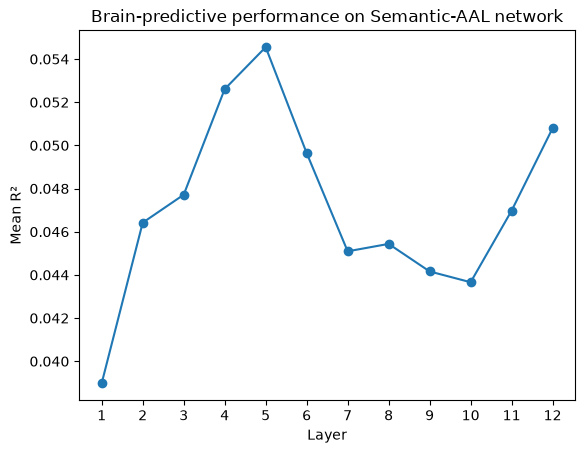

In [13]:
best_layer_semantic = np.argmax(mean_significant_r2_no_first_semanticAAL) +1
print(f"Best layer for the semantic AAL network: {best_layer_semantic}")
print(f"R^2 value on the best layer: {mean_significant_r2_no_first_semanticAAL[best_layer_semantic-1]:.3f}")
print(f"Mean R^2 value on significant voxels: {np.mean(mean_significant_r2_no_first_semanticAAL):.3f}")

# Plot layer-wise R2s
plt.plot(range(1, 13), mean_significant_r2_no_first_semanticAAL, marker='o')
plt.xlabel('Layer')
plt.ylabel('Mean R²')
plt.title('Brain-predictive performance on Semantic-AAL network')
plt.xticks(range(1,13))
plt.show()

# 2. Embedding predictibility on sentence length

As in the notebook, we predict sentence lenght based on BERTs embeddings per layer, to compare it to the brain predictivity we just assessed.

In [13]:
# get lenghts of sentences and Kfold splits
lens = np.array([len(sent.split(' ')) for sent in sentences])
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [14]:
# create a pipeline for predictions
ridge_pipeline = Pipeline([
      ("scaler", StandardScaler()),
      ("regressor", RidgeCV(alphas=np.arange(1,10))),
  ])

In [15]:
# fitting the pipeline and computing R2 scores 
r2_scores = []
for i in range(embeddings.shape[0]):
    this_layer_embeddings = embeddings[i]
    this_layer_r2 = cross_val_score(ridge_pipeline, this_layer_embeddings, lens, cv=cv, scoring="r2")
    r2_scores.append(this_layer_r2.mean())

sentence_length_r2 = np.asarray(r2_scores)
np.save('sentence_length_r2.npy', sentence_length_r2)

Best layer for sentence length prediction: 3
R^2 value on the best layer: 0.900
Mean R^2 value on all layers: 0.550


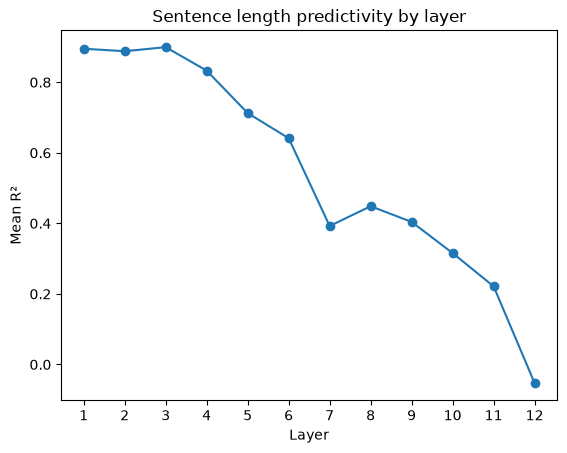

In [16]:
# Plot layer-wise R2s
sentence_length_r2_no_first = np.delete(sentence_length_r2, [0])

best_layer = np.argmax(sentence_length_r2_no_first) + 1
print(f"Best layer for sentence length prediction: {best_layer}")
print(f"R^2 value on the best layer: {sentence_length_r2_no_first[best_layer-1]:.3f}")
print(f"Mean R^2 value on all layers: {np.mean(sentence_length_r2_no_first):.3f}")

plt.plot(range(1, 13), sentence_length_r2_no_first, marker='o')
plt.xlabel('Layer')
plt.ylabel('Mean R²')
plt.title('Sentence length predictivity by layer')
plt.xticks(range(1, 13))
plt.show()

# 3. Embedding predictibility on topic 

Now we do the same thing for the topic predictions. Note that since this is a classification task, we will use accuracy as our metric.

In [17]:
# create a pipeline for predictions
logistic_pipeline = Pipeline([
      ("scaler", StandardScaler()),
      ("regressor", LogisticRegression(random_state=0)),
  ])

In [18]:
# fitting the pipeline and computing accuracy scores 
accuracy_scores = []
for i in range(embeddings.shape[0]):
  this_layer_embeddings = embeddings[i]
  this_layer_accuracy_scores = cross_val_score(logistic_pipeline, this_layer_embeddings, topic_list, cv=cv, scoring="accuracy")
  accuracy_scores.append(this_layer_accuracy_scores.mean())

topic_accuracy = np.asarray(accuracy_scores)
np.save('topic_accuracy.npy', topic_accuracy)

Best layer for topic prediction: 12
Accuracy value on the best layer: 0.846
Mean accuracy value across al layers: 0.704


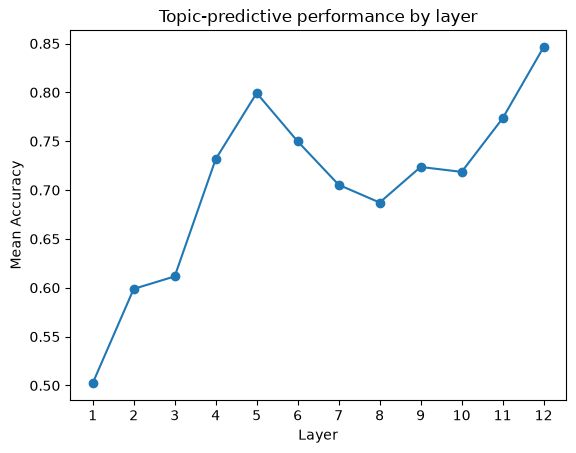

In [19]:
# Plot layer wise accuracy
topic_accuracy_no_first = np.delete(topic_accuracy, [0])

best_layer = np.argmax(topic_accuracy_no_first) + 1
print(f"Best layer for topic prediction: {best_layer}")
print(f"Accuracy value on the best layer: {topic_accuracy_no_first[best_layer - 1]:.3f}")
print(f"Mean accuracy value across al layers: {np.mean(topic_accuracy_no_first):.3f}")

plt.plot(range(1, 13), topic_accuracy_no_first, marker='o')
plt.xlabel('Layer')
plt.ylabel('Mean Accuracy')
plt.title('Topic-predictive performance by layer')
plt.xticks(range(1, 13))
plt.show()

# 4. Spearman test 

To assess where there is similarity between the R^2 values or accuracy values of different tasks, we now perform a statistical test.
Since we are comparing different types of measures and we are interested in assessing wether these measures increase and decrease across layers in a similar way, we decided to perform a Spearman test.

In [18]:
from scipy.stats import spearmanr

# Load brain-region predictivity
region_predictions = {
    "languageLH": np.load("mean_r2_languageLH.npy"),
    "LFFA": np.load("mean_r2_LFFA.npy"),
    "semanticAAL": np.load("mean_r2_semanticAAL.npy"),
}

# Load linguistic-property predictivity
linguistic_property_predictions = {
    "sentence length": np.load("sentence_length_r2.npy"),
    "topic": np.load("topic_accuracy.npy"),
}

spearman_results = []

# loop over brain regions and linguistic properties
for region_name, region_scores in region_predictions.items():
    for property_name, property_scores in linguistic_property_predictions.items():

        # compare all layers except the embedding layer
        rho, p_value = spearmanr(region_scores[1:], property_scores[1:])
        print(f"Spearman correlation between {region_name} predictivity and {property_name} predictivity:")
        print(f"rho = {rho:.3f}, p = {p_value:.4f}")

        spearman_results.append({
            "comparison": (region_name, property_name),
            "rho": rho,
            "p_value": p_value,
        })

Spearman correlation between languageLH predictivity and sentence length predictivity:
rho = -0.280, p = 0.3786
Spearman correlation between languageLH predictivity and topic predictivity:
rho = 0.881, p = 0.0002
Spearman correlation between LFFA predictivity and sentence length predictivity:
rho = -0.497, p = 0.1006
Spearman correlation between LFFA predictivity and topic predictivity:
rho = 0.937, p = 0.0000
Spearman correlation between semanticAAL predictivity and sentence length predictivity:
rho = -0.126, p = 0.6967
Spearman correlation between semanticAAL predictivity and topic predictivity:
rho = 0.818, p = 0.0011


As for the p-values of the metrics for brain predictions we apply a correction to control the false discovery rate arising from multiple comparisons. In this case we use the Benjamin-Hocheberg correction across the six correlation tests to control the false discovery rate while retaining statistical power.

In [ ]:
import statsmodels
from statsmodels.stats.multitest import multipletests

# Extract the six raw p-values
p_values = [result["p_value"] for result in spearman_results]

# Apply Benjamini-Hochberg correction
_, p_adjusted, _, _ = multipletests(p_values, method="fdr_bh")

# Print raw and adjusted p-values
for result, p_adj in zip(spearman_results, p_adjusted):
    region_name, property_name = result["comparison"]

    print(
        f"{region_name} vs. {property_name}: "
        f"rho = {result['rho']:.3f}, "
        f"raw p = {result['p_value']:.4g}, "
        f"adjusted p = {p_adj:.4g}"
    )

languageLH vs. sentence length: rho = -0.280, raw p = 0.3786, adjusted p = 0.4543
languageLH vs. topic: rho = 0.881, raw p = 0.0001527, adjusted p = 0.000458
LFFA vs. sentence length: rho = -0.497, raw p = 0.1006, adjusted p = 0.1509
LFFA vs. topic: rho = 0.937, raw p = 6.993e-06, adjusted p = 4.196e-05
semanticAAL vs. sentence length: rho = -0.126, raw p = 0.6967, adjusted p = 0.6967
semanticAAL vs. topic: rho = 0.818, raw p = 0.001143, adjusted p = 0.002286
